**[Course Home](../README.md) | [Conceptual Track](../conceptual/02_source_coding_kraft_and_huffman.ipynb) | [Prev: Ch 01: Quantifying Surprise](01_self_information_and_shannon_entropy.ipynb) | [Next: Ch 03: Relative Entropy & KL](03_relative_entropy_and_kl_divergence.ipynb)**

*Part I: Foundations of Uncertainty & Optimal Description — Chapter 02 of 11*

---

# Chapter 2: The Geometry of Compression — Python Laboratory
### *Kraft Inequality Verification, From-Scratch Huffman Encoding & Shannon Limits*

Welcome to the Python Laboratory for Chapter 2! In this session, we implement the complete algorithmic machinery of prefix trees, verify the Kraft inequality, build a from-scratch Huffman encoder/decoder, and test compression efficiency against theoretical entropy.

---

### Table of Contents
1. **Part 1: The Kraft-McMillan Inequality Checker**
2. **Part 2: From-Scratch Huffman Tree Engine**
3. **Part 3: Encoding & Lossless Bitstream Decoding**
4. **Part 4: Real-World Text Compression & Shannon Bound Comparison**
5. **Part 5: Multi-Panel Visualizations (Tree Topology & Bit Allocation)**
6. **Part 6: Hands-On 3-Tier Scaffolding Challenges**


## Part 1: The Kraft-McMillan Inequality Checker

### Theoretical Foundations & Code Space Geometry
A code $\mathcal{C} = \{c_1, c_2, \dots, c_K\}$ is **prefix-free** (or *instantaneous*) if no codeword $c_i$ is a prefix of any other codeword $c_j$ ($i \ne j$). This property allows a streaming decoder to identify codeword boundaries immediately without lookahead or delimiters.

1. **Kraft's Inequality**:
   For any $D$-ary prefix-free code with codeword lengths $\ell_1, \ell_2, \dots, \ell_K$ (where $D = 2$ for binary):
   $$K_{\text{sum}} = \sum_{i=1}^K D^{-\ell_i} \le 1$$
   Conversely, if a set of lengths $\{\ell_i\}$ satisfies this inequality, there exists a prefix-free code having those exact lengths.

2. **McMillan's Theorem**:
   Extends the bound to **all uniquely decodable codes**: even if a code is non-prefix, if it is uniquely decodable, its codeword lengths must satisfy $\sum D^{-\ell_i} \le 1$. Therefore, sacrificing the instantaneous prefix property cannot yield shorter average lengths.

3. **Geometric Budget in $[0, 1)$**:
   In the binary interval $[0, 1)$, assigning a codeword of length $\ell_i$ reserves a dyadic interval of width $2^{-\ell_i}$.
   - If $\sum 2^{-\ell_i} < 1$: the code is *incomplete* (budget is unexhausted; shorter codewords could be assigned).
   - If $\sum 2^{-\ell_i} = 1$: the code is *complete* (every leaf of the binary tree is occupied).
   - If $\sum 2^{-\ell_i} > 1$: the code words inevitably collide or overlap, making unique decoding impossible.

In [1]:
import heapq
from collections import Counter, namedtuple
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def kraft_sum(lengths, base=2):
    """Compute sum(base^-l_i) to check Kraft's inequality."""
    lengths = np.asarray(lengths, dtype=float)
    return np.sum(base ** (-lengths))

def is_valid_prefix_code(lengths, base=2):
    k_sum = kraft_sum(lengths, base)
    return k_sum <= 1.0 + 1e-12, k_sum

# Test valid vs invalid length sets
lengths_valid = [1, 2, 3, 3] # e.g. '0', '10', '110', '111' -> 1/2 + 1/4 + 1/8 + 1/8 = 1.0
lengths_invalid = [1, 1, 2]   # 1/2 + 1/2 + 1/4 = 1.25 > 1.0 (impossible!)

val_ok, sum_val = is_valid_prefix_code(lengths_valid)
inval_ok, sum_inval = is_valid_prefix_code(lengths_invalid)

print(f"Lengths {lengths_valid}: Valid={val_ok} (Kraft Sum = {sum_val:.3f})")
print(f"Lengths {lengths_invalid}: Valid={inval_ok} (Kraft Sum = {sum_inval:.3f} -> VIOLATION!)")


Lengths [1, 2, 3, 3]: Valid=True (Kraft Sum = 1.000)
Lengths [1, 1, 2]: Valid=False (Kraft Sum = 1.250 -> VIOLATION!)


## Part 2: From-Scratch Huffman Tree Engine

### Algorithmic Mechanics of Optimal Prefix Trees
Given an alphabet $\mathcal{X} = \{s_1, \dots, s_K\}$ with probabilities $P = (p_1, \dots, p_K)$, we seek integer codeword lengths $\ell_i \in \mathbb{Z}^+$ that minimize expected length:
$$L = \sum_{i=1}^K p_i \ell_i \quad \text{subject to} \quad \sum_{i=1}^K 2^{-\ell_i} \le 1$$

**David Huffman's Greedy Strategy (1952)**:
Huffman established two invariant properties of optimal prefix codes:
1. The two least probable symbols ($s_j, s_k$) must be assigned the longest codewords, and can be chosen to be siblings differing only in their final bit (`0` vs `1`).
2. Merging these two symbols into a composite parent node with weight $w = p_j + p_k$ reduces the problem to an optimal code over $K-1$ symbols.

**Algorithm Complexity**:
Using a binary min-heap priority queue, building the tree requires $\mathcal{O}(K \log K)$ operations. Traversing root-to-leaf assigns binary labels (`0` for left branches, `1` for right branches).

In [2]:
class HuffmanNode:
    def __init__(self, weight, symbol=None, left=None, right=None):
        self.weight = weight
        self.symbol = symbol
        self.left = left
        self.right = right

    def __lt__(self, other):
        return self.weight < other.weight

def build_huffman_tree(text_or_freqs):
    if isinstance(text_or_freqs, str):
        freqs = Counter(text_or_freqs)
    else:
        freqs = text_or_freqs
        
    heap = [HuffmanNode(weight=w, symbol=sym) for sym, w in freqs.items()]
    heapq.heapify(heap)
    
    while len(heap) > 1:
        lo = heapq.heappop(heap)
        hi = heapq.heappop(heap)
        parent = HuffmanNode(weight=lo.weight + hi.weight, symbol=None, left=lo, right=hi)
        heapq.heappush(heap, parent)
        
    root = heap[0]
    return root, freqs

def generate_codebook(root, prefix="", codebook=None):
    if codebook is None:
        codebook = {}
    if root.symbol is not None:
        codebook[root.symbol] = prefix
    else:
        if root.left:
            generate_codebook(root.left, prefix + "0", codebook)
        if root.right:
            generate_codebook(root.right, prefix + "1", codebook)
    return codebook

# Test on a small alphabet
toy_freqs = {'E': 45, 'T': 25, 'A': 15, 'O': 10, 'Z': 5}
tree_toy, _ = build_huffman_tree(toy_freqs)
toy_codes = generate_codebook(tree_toy)

for sym in sorted(toy_codes.keys(), key=lambda s: -toy_freqs[s]):
    print(f"Symbol '{sym}' (freq={toy_freqs[sym]}%): Code='{toy_codes[sym]}' (len={len(toy_codes[sym])})")


Symbol 'E' (freq=45%): Code='0' (len=1)
Symbol 'T' (freq=25%): Code='10' (len=2)
Symbol 'A' (freq=15%): Code='110' (len=3)
Symbol 'O' (freq=10%): Code='1111' (len=4)
Symbol 'Z' (freq=5%): Code='1110' (len=4)


## Part 3: Encoding & Lossless Bitstream Decoding

### Stream Processing & Instantaneous Decodability
1. **Encoding**:
   Given a source message $\mathbf{s} = (s_1, s_2, \dots, s_m)$, the encoder maps each character to its variable-length binary codeword and concatenates them:
   $$\mathbf{b} = c(s_1) \circ c(s_2) \circ \cdots \circ c(s_m)$$

2. **Instantaneous Tree Traversal Decoding**:
   Because the code is strictly prefix-free, no delimiters or space markers are needed:
   - Begin at the tree root.
   - For each incoming bit, traverse left (`0`) or right (`1`).
   - When a leaf node is reached, immediately emit the decoded symbol and reset to the root.
   - Processing time is linear in the number of bits: $\mathcal{O}(B)$ where $B = |\mathbf{b}|$, achieving provably lossless decompression.

In [3]:
def huffman_encode(text, codebook):
    return "".join(codebook[char] for char in text)

def huffman_decode(bitstring, root):
    decoded = []
    curr = root
    for bit in bitstring:
        curr = curr.left if bit == "0" else curr.right
        if curr.symbol is not None:
            decoded.append(curr.symbol)
            curr = root
    return "".join(decoded)

original_msg = "TEE_TO_TEA_AT_EAT"
tree_msg, _ = build_huffman_tree(original_msg)
msg_codebook = generate_codebook(tree_msg)
encoded_bits = huffman_encode(original_msg, msg_codebook)
decoded_msg = huffman_decode(encoded_bits, tree_msg)

print(f"Original Text:  '{original_msg}' ({len(original_msg)*8} raw ASCII bits)")
print(f"Encoded Bits:   '{encoded_bits}' ({len(encoded_bits)} compressed bits)")
print(f"Decoded Text:   '{decoded_msg}'")
print(f"Lossless Round-Trip Verified: {original_msg == decoded_msg}")
print(f"Compression Ratio: {len(encoded_bits) / (len(original_msg)*8) * 100:.1f}% of original size")


Original Text:  'TEE_TO_TEA_AT_EAT' (136 raw ASCII bits)
Encoded Bits:   '11010100111000011011010010111000110111' (38 compressed bits)
Decoded Text:   'TEE_TO_TEA_AT_EAT'
Lossless Round-Trip Verified: True
Compression Ratio: 27.9% of original size


## Part 4: Real-World Text Compression & Shannon Bound Comparison

### Shannon's Source Coding Theorem & Performance Metrics
Claude Shannon established the fundamental performance limit for lossless data compression:
$$H(X) \le L < H(X) + 1 \quad [\text{bits/symbol}]$$
where:
- **Entropy** $H(X) = -\sum_{i=1}^K p_i \log_2 p_i$ is the absolute theoretical lower limit of lossless compression.
- **Expected Length** $L = \sum_{i=1}^K p_i \ell_i$ is the average bits per symbol achieved by the code.

**Key Performance Metrics**:
1. **Coding Redundancy**:
   $$R = L - H(X) \ge 0 \quad [\text{bits/symbol}]$$
2. **Coding Efficiency**:
   $$\eta = \frac{H(X)}{L} \times 100\% \le 100\%$$
3. **Space Savings vs. Fixed-Length Code**:
   A fixed-length code over $K$ unique symbols requires $B_{\text{fixed}} = \lceil \log_2 K \rceil$ bits/symbol.
   $$\text{Savings} = \left(1 - \frac{L}{B_{\text{fixed}}}\right) \times 100\%$$

In [4]:
corpus = """information theory is a mathematical framework for quantifying the transmission storage and processing of information. it was originally formulated by claude shannon in nineteen forty-eight to find fundamental limits on signal processing and communication operations."""

root_corpus, freqs_corpus = build_huffman_tree(corpus)
codebook_corpus = generate_codebook(root_corpus)

total_chars = len(corpus)
probs = {char: count / total_chars for char, count in freqs_corpus.items()}

# 1. Theoretical Shannon Entropy
shannon_h = -sum(p * np.log2(p) for p in probs.values())

# 2. Average Huffman Code Length L = sum(p_i * l_i)
avg_code_len = sum(probs[char] * len(codebook_corpus[char]) for char in probs)

# 3. Kraft Sum
k_sum = sum(2**(-len(codebook_corpus[char])) for char in probs)

print("="*60)
print(f"Corpus Size:               {total_chars} characters ({len(probs)} unique symbols)")
print(f"Theoretical Shannon H(X):  {shannon_h:.4f} bits/symbol")
print(f"Average Huffman Length L:  {avg_code_len:.4f} bits/symbol")
print(f"Coding Redundancy (L - H): {avg_code_len - shannon_h:.4f} bits/symbol")
print(f"Kraft Inequality Sum:      {k_sum:.4f} (<= 1.0)")
print(f"Huffman Efficiency:        {(shannon_h / avg_code_len) * 100:.2f}%")
print("="*60)


Corpus Size:               267 characters (25 unique symbols)
Theoretical Shannon H(X):  4.1081 bits/symbol
Average Huffman Length L:  4.1386 bits/symbol
Coding Redundancy (L - H): 0.0305 bits/symbol
Kraft Inequality Sum:      1.0000 (<= 1.0)
Huffman Efficiency:        99.26%


## Part 5: Multi-Panel Visualizations

### Visualizing Bit Allocations & The Kraft Budget
We examine the geometry of the Huffman codebook across two complementary panels:
1. **Ideal vs. Actual Codeword Lengths**:
   Contrasts the continuous ideal self-information $\ell_i^* = -\log_2 p_i$ with the discrete integer Huffman lengths $\ell_i \in \mathbb{Z}^+$. The integer rounding gap illustrates where coding redundancy $R = L - H(X)$ originates.
2. **Cumulative Kraft Budget Consumption**:
   Plots the partial sums $S_k = \sum_{j=1}^k 2^{-\ell_j}$ as codewords are added in decreasing order of frequency. High-frequency characters consume massive chunks of code space (e.g., $2^{-2} = 0.25$), while rare characters consume narrow slices ($2^{-6} \approx 0.015$), bounded by $\sum 2^{-\ell_i} \le 1.0$.

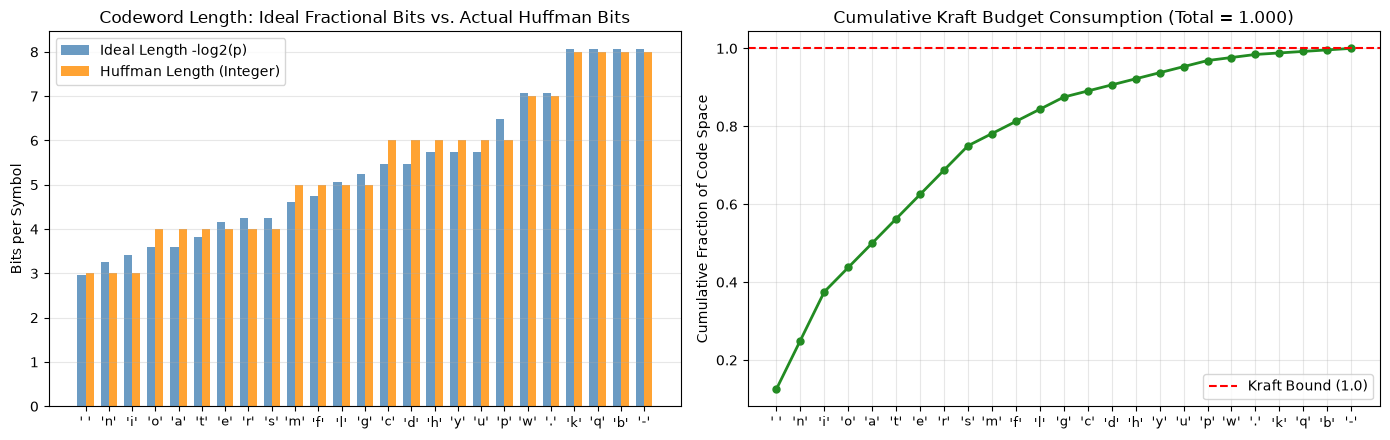

In [5]:
chars_sorted = sorted(probs.keys(), key=lambda c: -probs[c])
p_sorted = [probs[c] for c in chars_sorted]
ideal_bits = [-np.log2(p) for p in p_sorted]
actual_bits = [len(codebook_corpus[c]) for c in chars_sorted]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Ideal vs Actual Code Length
x_indices = np.arange(len(chars_sorted))
width = 0.35
ax1.bar(x_indices - width/2, ideal_bits, width=width, label="Ideal Length -log2(p)", color="steelblue", alpha=0.8)
ax1.bar(x_indices + width/2, actual_bits, width=width, label="Huffman Length (Integer)", color="darkorange", alpha=0.8)
ax1.set_xticks(x_indices)
ax1.set_xticklabels([f"'{c}'" if c != ' ' else "' '" for c in chars_sorted], fontsize=9)
ax1.set_title("Codeword Length: Ideal Fractional Bits vs. Actual Huffman Bits", fontsize=12)
ax1.set_ylabel("Bits per Symbol")
ax1.grid(True, alpha=0.3, axis="y")
ax1.legend()

# 2. Cumulative Kraft Consumption
kraft_consumptions = [2**(-l) for l in actual_bits]
cum_kraft = np.cumsum(kraft_consumptions)
ax2.plot(x_indices, cum_kraft, 'o-', color="forestgreen", lw=2, markersize=5)
ax2.axhline(1.0, color="red", linestyle="--", label="Kraft Bound (1.0)")
ax2.set_xticks(x_indices)
ax2.set_xticklabels([f"'{c}'" if c != ' ' else "' '" for c in chars_sorted], fontsize=9)
ax2.set_title(f"Cumulative Kraft Budget Consumption (Total = {cum_kraft[-1]:.3f})", fontsize=12)
ax2.set_ylabel("Cumulative Fraction of Code Space")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


## Part 6: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): The 4-Symbol Optimal Code
**Theoretical Context**:
A probability distribution is **dyadic** if every probability is an exact negative power of 2:
$$p_i = 2^{-k_i}, \quad k_i \in \mathbb{Z}^+$$
Here, $P = [0.5, 0.25, 0.125, 0.125] = [2^{-1}, 2^{-2}, 2^{-3}, 2^{-3}]$.

1. **Shannon Entropy**:
   $$H(X) = -\sum_{i=1}^4 p_i \log_2 p_i = 0.5(1) + 0.25(2) + 0.125(3) + 0.125(3) = 1.75 \quad [\text{bits}]$$

2. **Ideal Codeword Lengths**:
   $$\ell_i^* = -\log_2(2^{-k_i}) = k_i \in \{1, 2, 3, 3\}$$
   Because all ideal lengths are exact integers, Huffman coding assigns $\ell_i = k_i$, achieving:
   $$L = \sum_{i=1}^4 p_i \ell_i = 1.75 \quad [\text{bits}]$$
   Redundancy is exactly zero ($R = 0$) and efficiency is **$100\%$** ($\eta = 1.0$).
   The Kraft sum is strictly complete: $\sum 2^{-\ell_i} = 1/2 + 1/4 + 1/8 + 1/8 = 1.0$.

In [6]:
# Tier 1 Solution Space
t1_freqs = {'A': 50, 'B': 25, 'C': 12.5, 'D': 12.5}
t1_tree, _ = build_huffman_tree(t1_freqs)
t1_codes = generate_codebook(t1_tree)

t1_probs = np.array([0.50, 0.25, 0.125, 0.125])
t1_h = -np.sum(t1_probs * np.log2(t1_probs))
t1_l = sum(t1_probs[i] * len(t1_codes[s]) for i, s in enumerate(['A', 'B', 'C', 'D']))

print(f"Tier 1: H(X) = {t1_h:.3f} bits | L = {t1_l:.3f} bits")
print(f"Efficiency = {(t1_h / t1_l)*100:.1f}% (Dyadic probabilities 2^-k achieve zero redundancy!)")


Tier 1: H(X) = 1.750 bits | L = 1.750 bits
Efficiency = 100.0% (Dyadic probabilities 2^-k achieve zero redundancy!)


### 🟡 Diagnostic (Tier 2): Detecting Non-Prefix Ambiguity
**Theoretical Context**:
Let $\mathcal{C}$ be a set of binary strings. $\mathcal{C}$ is prefix-free if and only if:
$$\forall c_i, c_j \in \mathcal{C} \; (i \ne j) \implies c_i \text{ is not a prefix of } c_j$$
If $c_i$ is a prefix of $c_j$ ($c_j = c_i \circ u$ for some non-empty bitstring $u$), an instantaneous decoder reading $c_i$ cannot determine whether $c_i$ has finished or if additional bits are arriving to form $c_j$.

In the candidate codebook `{'A': '0', 'B': '1', 'C': '01'}`:
- Codeword `'0'` (symbol `A`) is a prefix of `'01'` (symbol `C`).
- Receiving the bit sequence `"01..."` creates ambiguity: is it `A` followed by `B`, or is it symbol `C`?
- This violates unique decodability without lookahead.

In [7]:
def is_prefix_free(codebook):
    codes = sorted(codebook.items(), key=lambda x: len(x[1]))
    for i in range(len(codes)):
        sym1, c1 = codes[i]
        for j in range(i + 1, len(codes)):
            sym2, c2 = codes[j]
            if c2.startswith(c1):
                return False, f"Conflict: '{sym1}' ({c1}) is a prefix of '{sym2}' ({c2})"
    return True, "Codebook is strictly prefix-free!"

test_codebook = {'A': '0', 'B': '1', 'C': '01'}
is_pf, reason = is_prefix_free(test_codebook)
print(f"Codebook check: {is_pf} -> {reason}")


Codebook check: False -> Conflict: 'A' (0) is a prefix of 'C' (01)


### 🔴 Capstone Challenge (Tier 3): The Arithmetic Coding Advantage
**The Integer Constraint Bottleneck**:
Huffman coding is constrained to assign an **integer number of bits** $\ell_i \in \{1, 2, \dots\}$ to each individual symbol.
When an outcome is near-certain (e.g. $p_1 = 0.98$ and $p_2 = 0.02$):
- Ideal lengths: $\ell_1^* = -\log_2(0.98) \approx 0.0291\text{ bits}$, $\ell_2^* = -\log_2(0.02) \approx 5.644\text{ bits}$.
- True Shannon Entropy:
  $$H(X) = -0.98 \log_2(0.98) - 0.02 \log_2(0.02) \approx 0.1414 \quad [\text{bits/symbol}]$$
- Because a binary prefix code over 2 symbols must assign at least 1 bit to each symbol (`0` and `1`), Huffman gives:
  $$L_{\text{Huffman}} = 0.98(1) + 0.02(1) = 1.0 \quad [\text{bits/symbol}]$$
  This incurs an enormous redundancy of $(1.0 - 0.1414)/0.1414 \approx 607\%$!

**The Arithmetic Coding Solution**:
Arithmetic coding eliminates this bottleneck by encoding an **entire block of $N$ symbols** into a single nested sub-interval $[a, b) \subset [0, 1)$ of width $W = \prod_{i=1}^N p(x_i)$. The total bits required for all $N$ symbols is $\lceil -\log_2 W \rceil + 1$, achieving an average per-symbol length of:
$$\frac{L_N}{N} \le H(X) + \frac{2}{N} \xrightarrow{N \to \infty} H(X)$$
allowing fractional-bit representation per symbol without combinatorial alphabet explosion.

In [8]:
p_extreme = np.array([0.98, 0.02])
h_extreme = -np.sum(p_extreme * np.log2(p_extreme))
# Huffman for 2 symbols MUST be 1 bit each
l_huffman = 1.0

print(f"True Shannon Entropy: {h_extreme:.4f} bits/symbol")
print(f"Huffman Average Length:{l_huffman:.4f} bits/symbol")
print(f"Excess Waste:          {(l_huffman - h_extreme)/h_extreme * 100:.1f}% excess bits!")
print("Arithmetic coding achieves fractional-bit efficiency by encoding entire message blocks into sub-intervals of [0, 1)!")


True Shannon Entropy: 0.1414 bits/symbol
Huffman Average Length:1.0000 bits/symbol
Excess Waste:          607.0% excess bits!
Arithmetic coding achieves fractional-bit efficiency by encoding entire message blocks into sub-intervals of [0, 1)!


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/02_source_coding_kraft_and_huffman.ipynb) | [Prev: Ch 01: Quantifying Surprise](01_self_information_and_shannon_entropy.ipynb) | [Next: Ch 03: Relative Entropy & KL](03_relative_entropy_and_kl_divergence.ipynb)**
